# About the Dataset

Data source: https://www.kaggle.com/datasets/vikrishnan/boston-house-prices

**Each record in the database describes a Boston suburb or town. The data was drawn from the Boston Standard Metropolitan Statistical Area (SMSA) in 1970. The attributes are deﬁned as follows taken from the UCI Machine Learning Repository**

**Feature**
- CRIM: per capita crime rate by town
- ZN: proportion of residential land zoned for lots over 25,000 sq.ft.
- INDUS: proportion of non-retail business acres per town
- CHAS: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
- NOX: nitric oxides concentration (parts per 10 million)
- RM: average number of rooms per dwelling
- AGE: proportion of owner-occupied units built prior to 1940
- DIS: weighted distances to ﬁve Boston employment centers
- RAD: index of accessibility to radial highways
- TAX: full-value property-tax rate per $10,000
- PTRATIO: pupil-teacher ratio by town 12.

- B: 1000(Bk−0.63)2 where Bk is the proportion of blacks by town 13.
- LSTAT: % lower status of the population

**target**
- MEDV: Median value of owner-occupied homes in $1000

We can see that the input attributes have a mixture of units.

#Data Loading

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vikrishnan/boston-house-prices")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'boston-house-prices' dataset.
Path to dataset files: /kaggle/input/boston-house-prices


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df = pd.read_csv(path+"/housing.csv", delimiter=r"\s+",names=column_names)
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [5]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2024/94023982.py:8: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(f"{path}/housing.csv", header=None, sep='\s+', names=column_names)


Using Colab cache for faster access to the 'boston-house-prices' dataset.


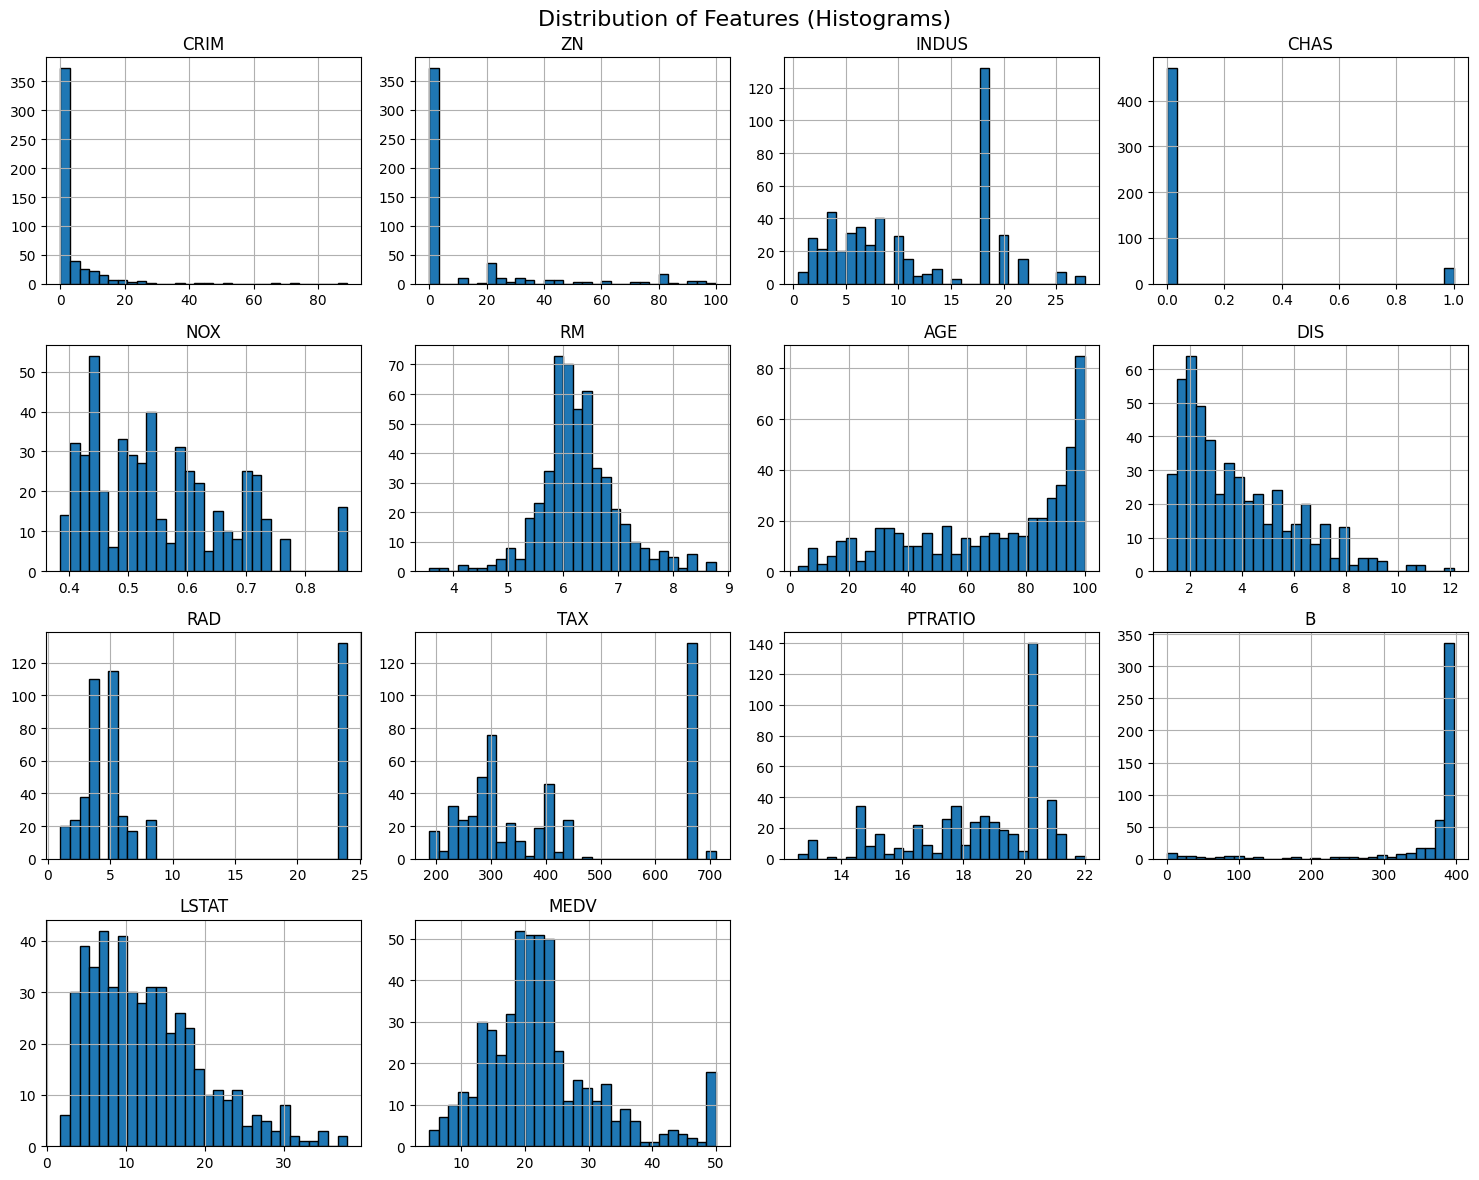

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub


path = kagglehub.dataset_download("vikrishnan/boston-house-prices")
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df = pd.read_csv(f"{path}/housing.csv", header=None, sep='\s+', names=column_names)


df.hist(bins=30, figsize=(15, 12), edgecolor='black')
plt.suptitle("Distribution of Features (Histograms)", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
df.groupby("RM")["CRIM"].mean()

,CRIM
RM,
3.561,4.55587
3.863,13.52220
4.138,19.60720
4.368,20.08490
4.519,45.74610
...,...
8.375,1.51902
8.398,0.52014
8.704,0.61154


[]

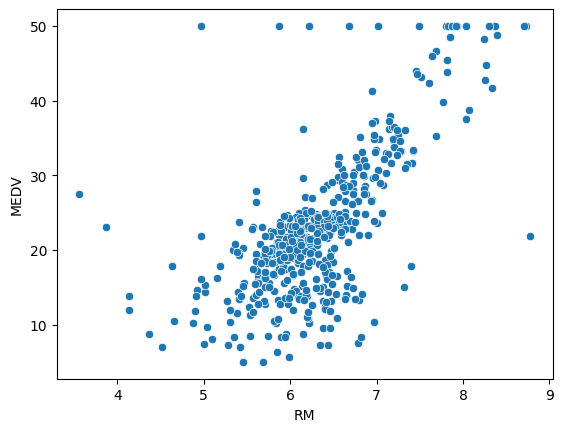

<Figure size 1200x500 with 0 Axes>

In [24]:
season_mean = sns.scatterplot(data=df, x="RM", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')


كلما زادت متوسط عدد الغرف زادت قيمه متوسط المنزل

In [11]:
df.groupby("LSTAT")["CRIM"].mean()

,CRIM
LSTAT,
1.73,1.46336
1.92,1.83377
1.98,0.03359
2.47,0.57529
2.87,0.08664
...,...
34.37,18.81100
34.41,1.62864
34.77,11.10810


[]

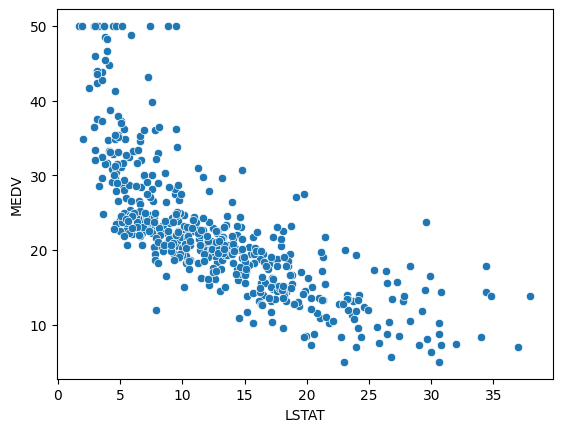

<Figure size 1200x500 with 0 Axes>

In [23]:
season_mean = sns.scatterplot(data=df, x="LSTAT", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

كلما زادت قيمه متوسط المنزل قلت نسبة الفئة الاجتماعية الأقل مكانة

[]

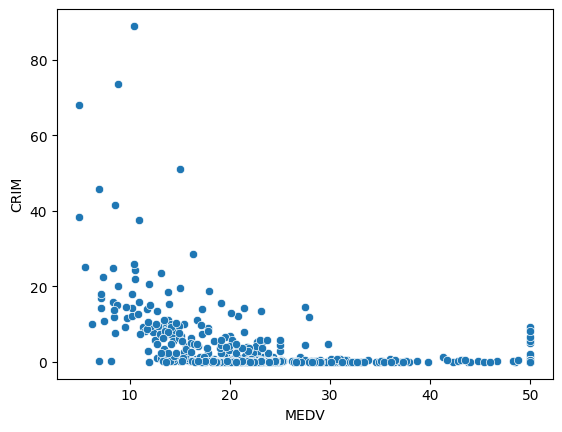

<Figure size 1200x500 with 0 Axes>

In [19]:
season_mean = sns.scatterplot(data=df, x="MEDV", y="CRIM")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

كلما قلت قيمه متوسط المنزل زادت زادت معدل الجريمه

[]

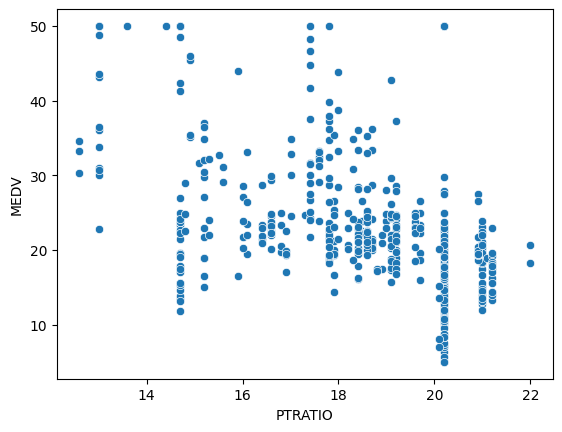

<Figure size 1200x500 with 0 Axes>

In [21]:
season_mean = sns.scatterplot(data=df, x="PTRATIO", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

كلمل زادت قيمه متوسط المنزل قل عدد الطلاب مقابل المعلم الواحد

[]

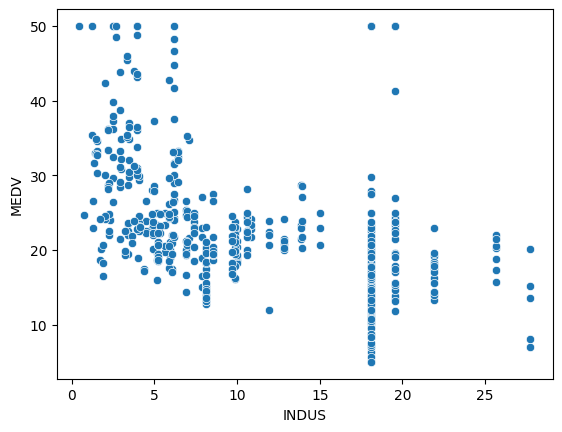

<Figure size 1200x500 with 0 Axes>

In [25]:
season_mean = sns.scatterplot(data=df, x="INDUS", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

كلما كانت المنطقه اكثر صناعيا اصبحت اقل سعرا

[]

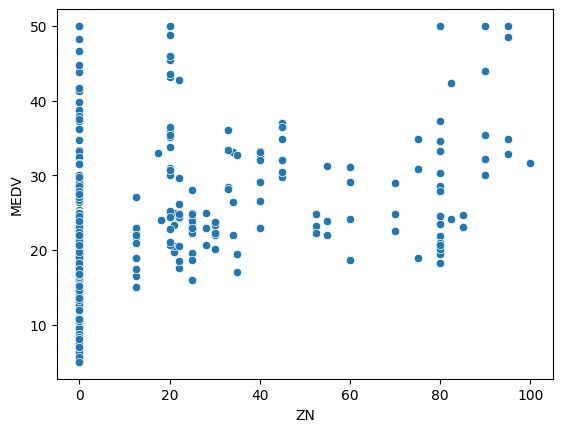

<Figure size 1200x500 with 0 Axes>

In [26]:
season_mean = sns.scatterplot(data=df, x="ZN", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

كلما احتوت المنطقه على مبانى سكنيه كبيره قلت قيمه متوسط سعر السكن بنسبه كبيره

[]

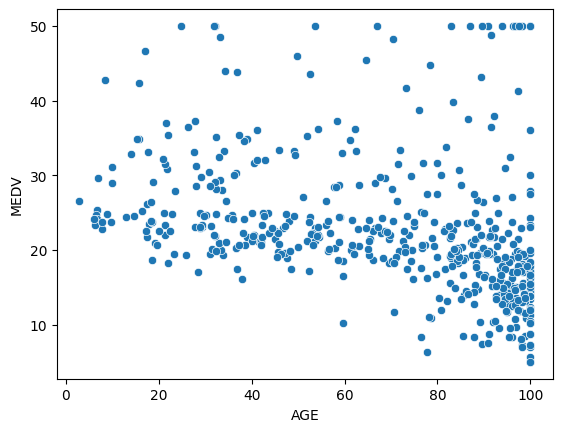

<Figure size 1200x500 with 0 Axes>

In [27]:
season_mean = sns.scatterplot(data=df, x="AGE", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

كلما احتوت المنطقه على مبانى قديمه او تاريخيه وجدنا ان سعر متوسط السكن زاد بشكل كير وملحوظ

[]

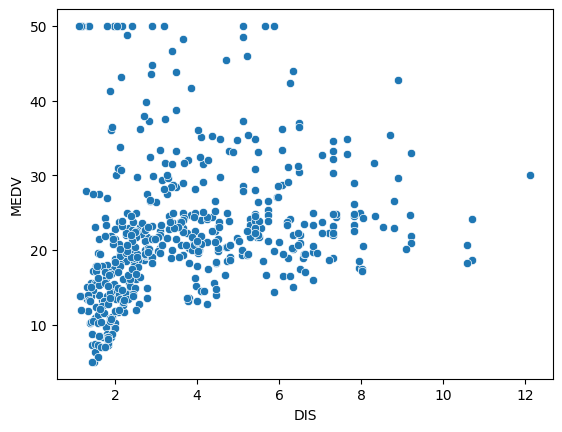

<Figure size 1200x500 with 0 Axes>

In [29]:
season_mean = sns.scatterplot(data=df, x="DIS", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

كلما كانت مكاتب التوظيف اقرب الى السكن كلما كانت متوسط قيمته اعلى

[]

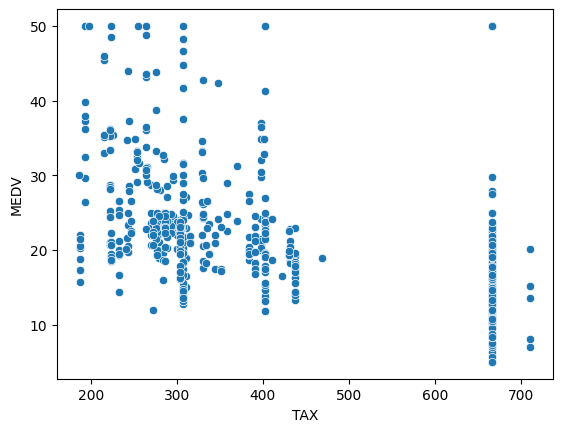

<Figure size 1200x500 with 0 Axes>

In [30]:
season_mean = sns.scatterplot(data=df, x="TAX", y="MEDV")

plt.figure(figsize=(12, 5))
season_mean.plot(kind='scatter')

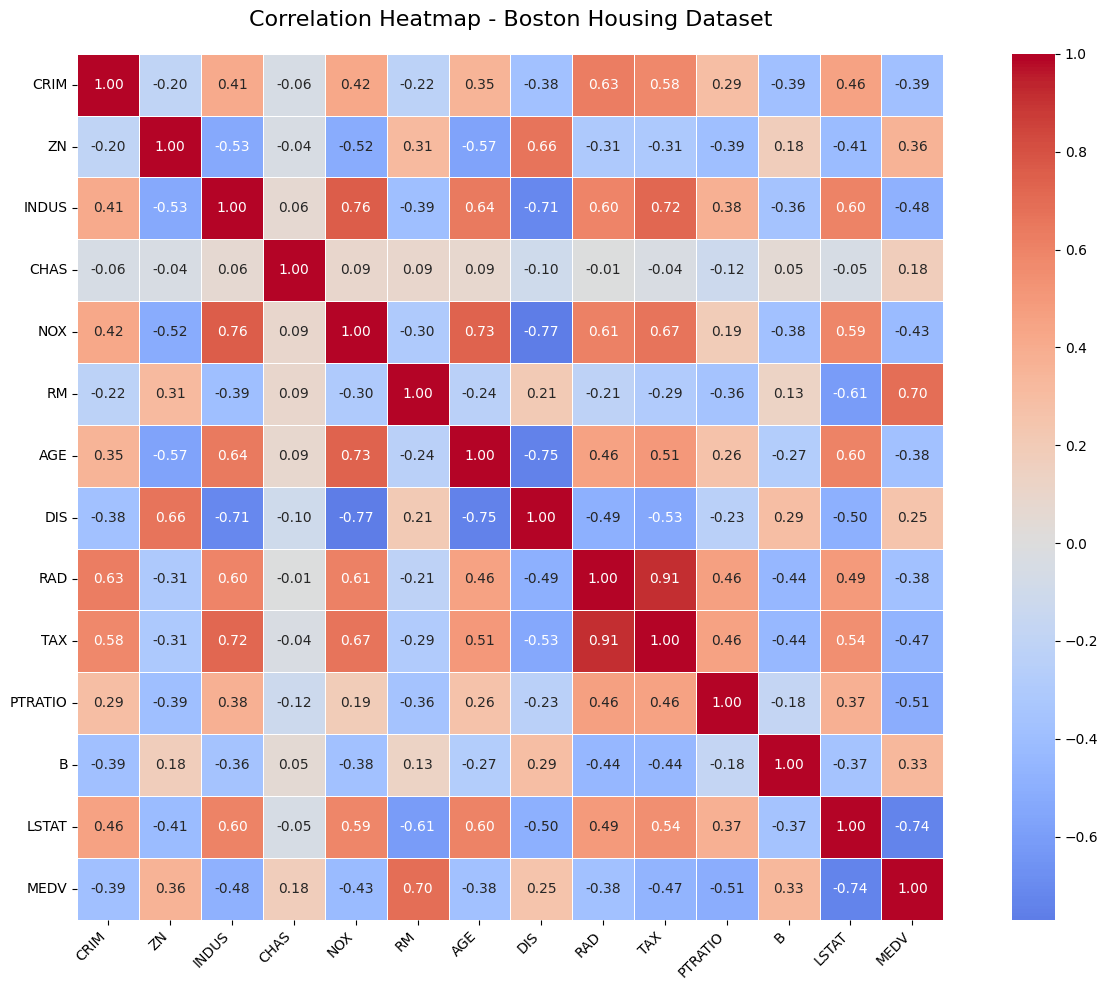

In [31]:

# Correlation Heatmap – Boston Housing Dataset

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
correlation_matrix = df.corr(numeric_only=True)

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0,
    square=True
)

plt.title('Correlation Heatmap - Boston Housing Dataset', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.isna().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


In [36]:
#ftest t test

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.639
Model:                            OLS   Adj. R-squared:                  0.637
Method:                 Least Squares   F-statistic:                     444.3
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          7.01e-112
Time:                        14:39:39   Log-Likelihood:                -1582.8
No. Observations:                 506   AIC:                             3172.
Df Residuals:                     503   BIC:                             3184.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.3583      3.173     -0.428      0.6

الفرق ما بين (r squared) وال(adj.r squared) قليل جدا وده يدل ان الداتا عندنا مش عشوائيه ، وكونهم مش قريبين من ال1 ده معناه ان الداتا عندنا مش كافيه ومحتاجين كمان داتا

In [37]:
#use linear regrission model

Mean Squared Error (MSE): 24.2911
R-squared Score (R²): 0.6688


In [38]:
#use random forest

Random Forest - Mean Squared Error (MSE): 7.9015
Random Forest - R-squared Score (R²): 0.8923


In [39]:
#use the svr

SVR - Mean Squared Error (MSE): 12.7382
SVR - R-squared Score (R²): 0.8263
